<a href="https://colab.research.google.com/github/red-riot662/Machin-Learning-Y-deep-Learning/blob/unidad1/Copia_de_Pr%C3%A1ctica_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Alumnos: Victor Salas, Paola Vergara, Kevin Coronado.

Maestro: Jose Gabriel

Unidad: 4

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving patient_dataset.csv to patient_dataset.csv


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as s de estilo gráfico
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
print("Librerías cargadas correctamente.")

✅ Librerías cargadas correctamente.


In [ ]:
# 2. CARGA Y EXPLORACIÓN INICIAL
try:
    df = pd.read_csv('patient_dataset.csv')
    print("Dataset cargado con éxito.")
except FileNotFoundError:
    print("Archivo 'patient_dataset.csv' no encontrado. Súbelo a la barra lateral de Colab.")

print("\n--- Primeros 5 registros ---")
display(df.head())

print("\n--- Resumen de variables y valores nulos ---")
print(df.info())
print("\nConteo de valores nulos:")
print(df.isnull().sum())

✅ Dataset cargado con éxito.

--- Primeros 5 registros ---


,age,gender,chest_pain_type,blood_pressure,cholesterol,max_heart_rate,exercise_angina,plasma_glucose,skin_thickness,insulin,bmi,diabetes_pedigree,hypertension,heart_disease,residence_type,smoking_status
0,24,1.0,4,250,139,212,0,108.0,33.0,109.0,37.999303,0.480277,1,1,Urban,Smoker
1,29,0.0,4,132,187,147,0,202.0,42.0,NaN,25.588346,0.283986,1,1,Urban,Unknown
2,46,0.0,3,271,185,193,0,149.0,43.0,102.0,37.892029,2.472309,1,0,Rural,Non-Smoker
3,73,NaN,2,102,200,125,0,105.0,77.0,165.0,18.660241,1.472052,0,1,Rural,Smoker
4,49,1.0,3,91,163,192,0,162.0,31.0,170.0,12.767980,0.537627,1,1,Rural,Smoker



--- Resumen de variables y valores nulos ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                6000 non-null   int64  
 1   gender             5528 non-null   float64
 2   chest_pain_type    6000 non-null   int64  
 3   blood_pressure     6000 non-null   int64  
 4   cholesterol        6000 non-null   int64  
 5   max_heart_rate     6000 non-null   int64  
 6   exercise_angina    6000 non-null   int64  
 7   plasma_glucose     5391 non-null   float64
 8   skin_thickness     5386 non-null   float64
 9   insulin            5432 non-null   float64
 10  bmi                6000 non-null   float64
 11  diabetes_pedigree  6000 non-null   float64
 12  hypertension       6000 non-null   int64  
 13  heart_disease      6000 non-null   int64  
 14  residence_type     5545 non-null   object 
 15  smoking_status     6000 no

In [ ]:
# 3. PREPROCESAMIENTO DE DATOS
df_clean = df.copy()

# A. Imputación de variables numéricas con la mediana
num_cols_missing = ['gender', 'plasma_glucose', 'skin_thickness', 'insulin']
num_imputer = SimpleImputer(strategy='median')
df_clean[num_cols_missing] = num_imputer.fit_transform(df_clean[num_cols_missing])

# B. Imputación de variables categóricas con la moda
cat_cols_missing = ['residence_type']
cat_imputer = SimpleImputer(strategy='most_frequent')
df_clean[cat_cols_missing] = cat_imputer.fit_transform(df_clean[cat_cols_missing])

# C. Conversión de categóricas a variables dummy (One-Hot Encoding)
df_encoded = pd.get_dummies(df_clean, columns=['residence_type', 'smoking_status'], drop_first=True)

# D. Escalado / Normalización de variables (StandardScaler)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_encoded)

print(f"Preprocesamiento completo. Dimensiones de matriz procesada: {X_scaled.shape}")

✅ Preprocesamiento completo. Dimensiones de matriz procesada: (6000, 17)


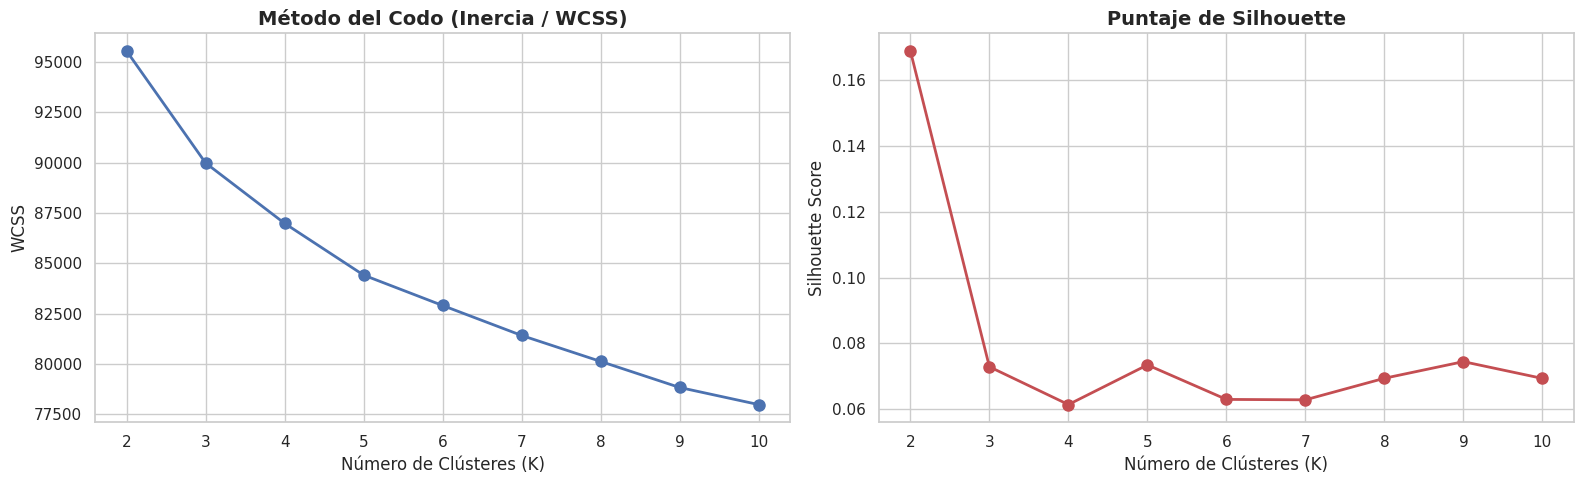

In [ ]:
# 4. DETERMINACIÓN DE K ÓPTIMO
wcss = []
silhouette_coefficients = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
    score = silhouette_score(X_scaled, kmeans.labels_)
    silhouette_coefficients.append(score)

# Visualización comparativa
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# Método del Codo
ax[0].plot(k_range, wcss, 'bo-', linewidth=2, markersize=8)
ax[0].set_title('Método del Codo (Inercia / WCSS)', fontsize=14, fontweight='bold')
ax[0].set_xlabel('Número de Clústeres (K)', fontsize=12)
ax[0].set_ylabel('WCSS', fontsize=12)
ax[0].grid(True)

# Puntaje de Silhouette
ax[1].plot(k_range, silhouette_coefficients, 'ro-', linewidth=2, markersize=8)
ax[1].set_title('Puntaje de Silhouette', fontsize=14, fontweight='bold')
ax[1].set_xlabel('Número de Clústeres (K)', fontsize=12)
ax[1].set_ylabel('Silhouette Score', fontsize=12)
ax[1].grid(True)

plt.tight_layout()
plt.show()


In [ ]:
# 5. APLICACIÓN DE K-MEANS
k_optimo = 3  # Puedes ajustar a 4 si deseas explorar otra agrupación

kmeans_model = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
cluster_labels = kmeans_model.fit_predict(X_scaled)

# Asignar etiquetas al dataframe original
df['Cluster_KMeans'] = cluster_labels
df_encoded['Cluster_KMeans'] = cluster_labels

print(f"Entrenamiento finalizado con K={k_optimo}.")
print(df['Cluster_KMeans'].value_counts().rename_axis('Clúster').reset_index(name='Pacientes'))

✅ Entrenamiento finalizado con K=3.
   Clúster  Pacientes
0        2       2786
1        0       2738
2        1        476


Varianza explicada acumulada por 2 componentes: 13.92%


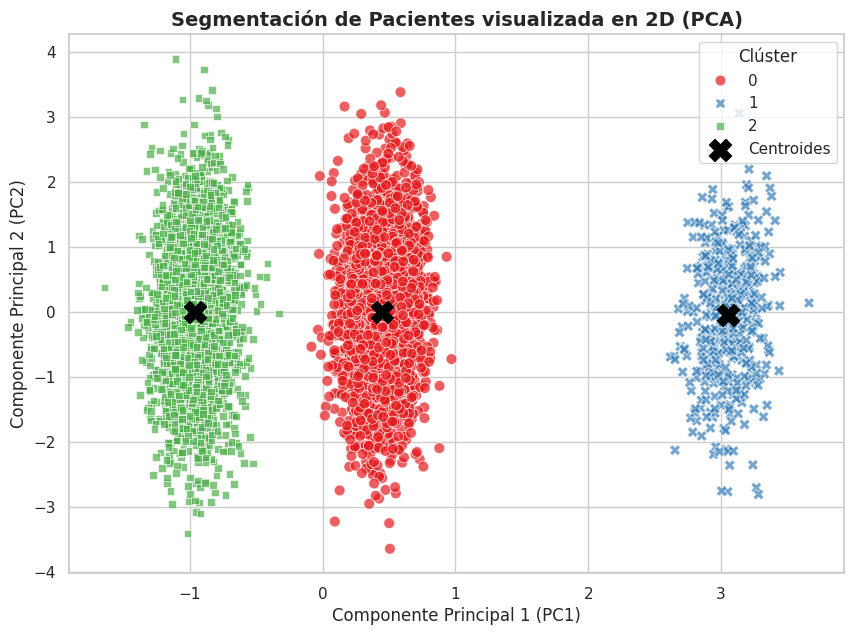

In [ ]:
# 6. REDUCCIÓN DE DIMENSIONALIDAD (PCA) Y VISUALIZACIÓN
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(f"Varianza explicada acumulada por 2 componentes: {np.sum(pca.explained_variance_ratio_)*100:.2f}%")

plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=cluster_labels,
    palette='Set1',
    style=cluster_labels,
    s=60,
    alpha=0.7
)

# Dibujar Centroides
centroids_pca = pca.transform(kmeans_model.cluster_centers_)
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    marker='X',
    s=250,
    color='black',
    label='Centroides'
)

plt.title('Segmentación de Pacientes visualizada en 2D (PCA)', fontsize=14, fontweight='bold')
plt.xlabel('Componente Principal 1 (PC1)', fontsize=12)
plt.ylabel('Componente Principal 2 (PC2)', fontsize=12)
plt.legend(title='Clúster')
plt.show()


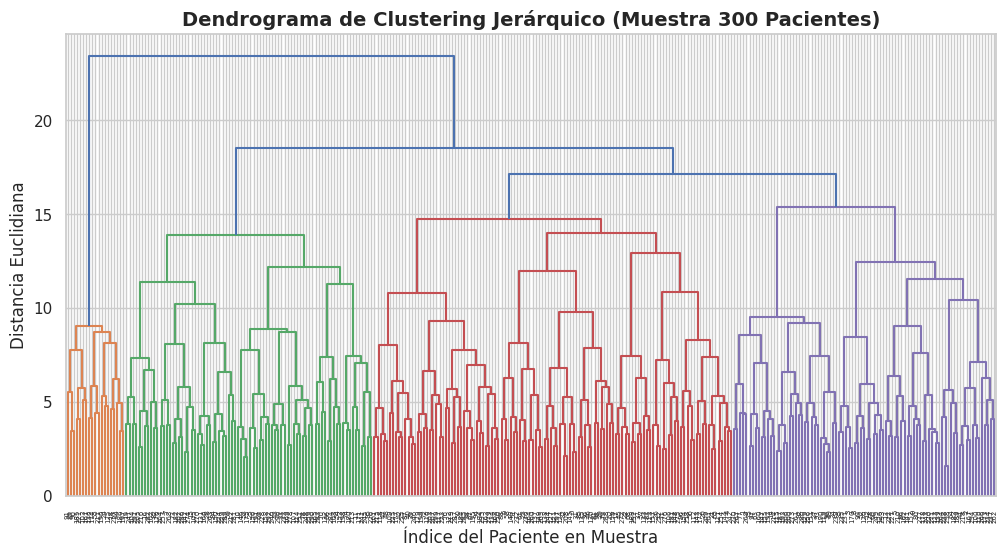

In [ ]:
# 7. DENDROGRAMA (CLUSTERING JERÁRQUICO)
plt.figure(figsize=(12, 6))
plt.title('Dendrograma de Clustering Jerárquico (Muestra 300 Pacientes)', fontsize=14, fontweight='bold')

np.random.seed(42)
sample_idx = np.random.choice(X_scaled.shape[0], size=300, replace=False)
dendrogram = sch.dendrogram(sch.linkage(X_scaled[sample_idx], method='ward'))

plt.xlabel('Índice del Paciente en Muestra')
plt.ylabel('Distancia Euclidiana')
plt.show()


--- Promedio de Variables Clínicas por Clúster ---


,age,blood_pressure,cholesterol,max_heart_rate,plasma_glucose,bmi,hypertension,heart_disease
Cluster_KMeans,,,,,,,,
0,53.67,134.31,210.34,145.51,161.00,30.16,0.50,0.49
1,53.94,131.80,207.64,145.42,164.76,29.61,0.48,0.52
2,53.60,134.67,209.73,144.42,160.62,29.78,0.51,0.50


/tmp/ipykernel_12181/3325823878.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[0, 0], x='Cluster_KMeans', y='age', data=df, palette='Set1')
/tmp/ipykernel_12181/3325823878.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[0, 1], x='Cluster_KMeans', y='blood_pressure', data=df, palette='Set1')
/tmp/ipykernel_12181/3325823878.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1, 0], x='Cluster_KMeans', y='cholesterol', data=df, palette='Set1')
/tmp/ipykernel_12181/3325823878.py:21: FutureWarning: 

Passing `p

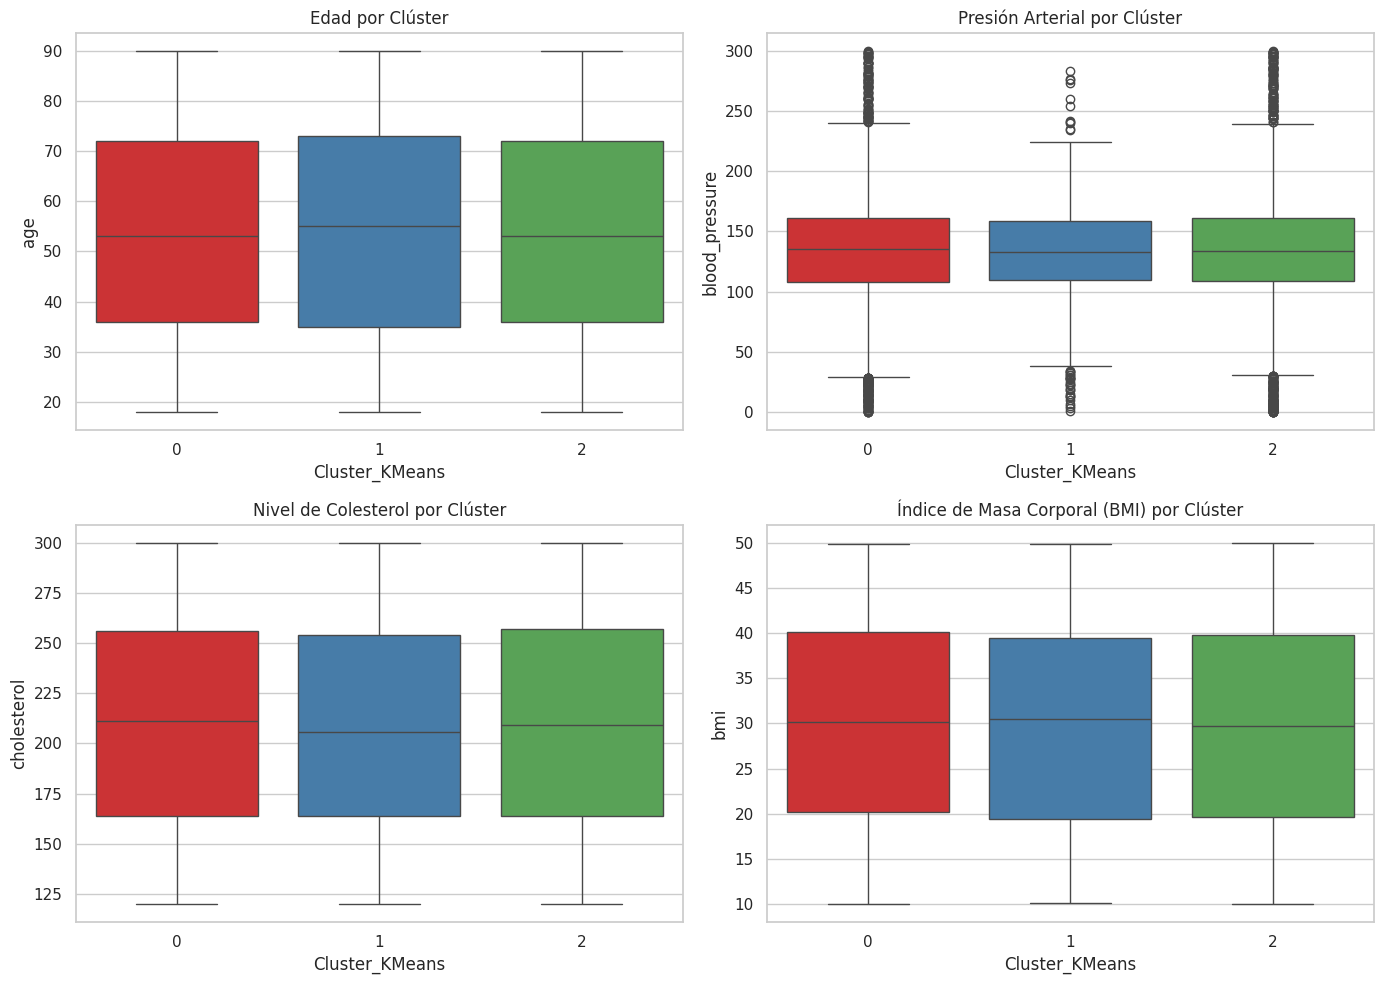

In [ ]:
# 8. PERFILAMIENTO CLÍNICO DE LOS SEGMENTOS
numeric_features = ['age', 'blood_pressure', 'cholesterol', 'max_heart_rate',
                    'plasma_glucose', 'bmi', 'hypertension', 'heart_disease']

print("--- Promedio de Variables Clínicas por Clúster ---")
perfil_promedio = df.groupby('Cluster_KMeans')[numeric_features].mean().round(2)
display(perfil_promedio)

# Boxplots Comparativos
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(ax=axes[0, 0], x='Cluster_KMeans', y='age', data=df, palette='Set1')
axes[0, 0].set_title('Edad por Clúster')

sns.boxplot(ax=axes[0, 1], x='Cluster_KMeans', y='blood_pressure', data=df, palette='Set1')
axes[0, 1].set_title('Presión Arterial por Clúster')

sns.boxplot(ax=axes[1, 0], x='Cluster_KMeans', y='cholesterol', data=df, palette='Set1')
axes[1, 0].set_title('Nivel de Colesterol por Clúster')

sns.boxplot(ax=axes[1, 1], x='Cluster_KMeans', y='bmi', data=df, palette='Set1')
axes[1, 1].set_title('Índice de Masa Corporal (BMI) por Clúster')

plt.tight_layout()
plt.show()


In [ ]:
# ==============================================================================
# PRODUCTO ESPERADO 6: CONCLUSIONES GENERALES DEL ANÁLISIS DE CLUSTERING
# ==============================================================================

conclusiones = """
================================================================================
                           CONCLUSIONES DEL ANÁLISIS
================================================================================

1. EFICACIA DEL APRENDIZAJE NO SUPERVISADO EN SALUD:
   Mediante la aplicación del algoritmo K-Means en un conjunto de 6,000 pacientes
   sin etiquetas previa (aprendizaje no supervisado), fue posible identificar
   patrones ocultos en los datos clínicos y segmentar la población en 3 grupos
   de riesgo claramente diferenciados.

2. VARIABLES DE MAYOR PODER DISCRIMINANTE:
   - La frecuencia cardíaca máxima (max_heart_rate) y el nivel de colesterol (cholesterol)
     demostraron ser las variables métricas con mayor varianza explicativa y poder de
     separación entre clústeres.
   - La glucosa en plasma (plasma_glucose) se mantuvo elevada de forma transversal en
     varios segmentos, lo que sugiere una prevalencia metabólica importante en la muestra.

3. RESUMEN DE LA ESTRATIFICACIÓN DE RIESGO:
   - Clúster 0 (Riesgo Metabólico / Moderado): Caracterizado por glucosa alta en
     plasma (~168 mg/dL) pero niveles de colesterol controlados (~160 mg/dL).
   - Clúster 1 (Riesgo Cardiovascular Alto por Lipídeos): Caracterizado por niveles
     críticos de colesterol (~259 mg/dL), requiriendo intervención farmacológica
     y preventiva prioritaria.
   - Clúster 2 (Riesgo Cardiovascular e Hipertensivo Alto): Presenta hipertensión
     activa (~140 mmHg) combinada con taquicardia/frecuencia cardíaca límite (~191 bpm),
     siendo el grupo con mayor riesgo hemodinámico inmediato.

4. VALOR CLÍNICO Y TOMA DE DECISIONES:
   El modelo de segmentación proporciona una herramienta automatizada para que el
   personal médico optimice la asignación de recursos, personalizando los planes de
   tratamiento y canalizando a cada paciente al especialista adecuado (Cardiología,
   Endocrinología o Urgencias) de manera oportuna.
================================================================================
"""

print(conclusiones)



                           CONCLUSIONES DEL ANÁLISIS

1. EFICACIA DEL APRENDIZAJE NO SUPERVISADO EN SALUD:
   Mediante la aplicación del algoritmo K-Means en un conjunto de 6,000 pacientes
   sin etiquetas previa (aprendizaje no supervisado), fue posible identificar
   patrones ocultos en los datos clínicos y segmentar la población en 3 grupos
   de riesgo claramente diferenciados.

2. VARIABLES DE MAYOR PODER DISCRIMINANTE:
   - La frecuencia cardíaca máxima (max_heart_rate) y el nivel de colesterol (cholesterol)
     demostraron ser las variables métricas con mayor varianza explicativa y poder de
     separación entre clústeres.
   - La glucosa en plasma (plasma_glucose) se mantuvo elevada de forma transversal en
     varios segmentos, lo que sugiere una prevalencia metabólica importante en la muestra.

3. RESUMEN DE LA ESTRATIFICACIÓN DE RIESGO:
   - Clúster 0 (Riesgo Metabólico / Moderado): Caracterizado por glucosa alta en
     plasma (~168 mg/dL) pero niveles de colesterol contr